In [1]:
#| include: false
import matplotlib.pyplot as plt
import numpy as np
import polars as pl

from utils.style import COLORS, CYCLE, apply_style

apply_style()
np.set_printoptions(precision=4, suppress=True, linewidth=110)
_ = pl.Config.set_float_precision(4)

All the exercises use the Household Budget Survey (EPF) of 2025, loaded as
follows (the variables are described in `data/processed/epf/README.md`):

In [2]:
households = pl.read_csv("data/processed/epf/households.csv")

::: {#exr-tenure}
## Housing tenure
a) Build the table of absolute and relative frequencies of `tenure`, the tenure
   regime of the household's main dwelling.
b) Draw it as a bar chart.
c) What percentage of households rent their home, at market price or below it?
:::

::: {.callout-tip collapse="true"}
## Solution

In [3]:
table = (
    households["tenure"]
    .value_counts(sort=True, name="n_i")
    .with_columns(f_i=pl.col("n_i") / pl.col("n_i").sum())
)
table

tenure,n_i,f_i
Owned outright,"10,450",0.530
Owned with mortgage,5278,0.268
Rented,2780,0.141
Provided free,643,0.033
Provided at reduced cost,333,0.017
Rented below market,219,0.011


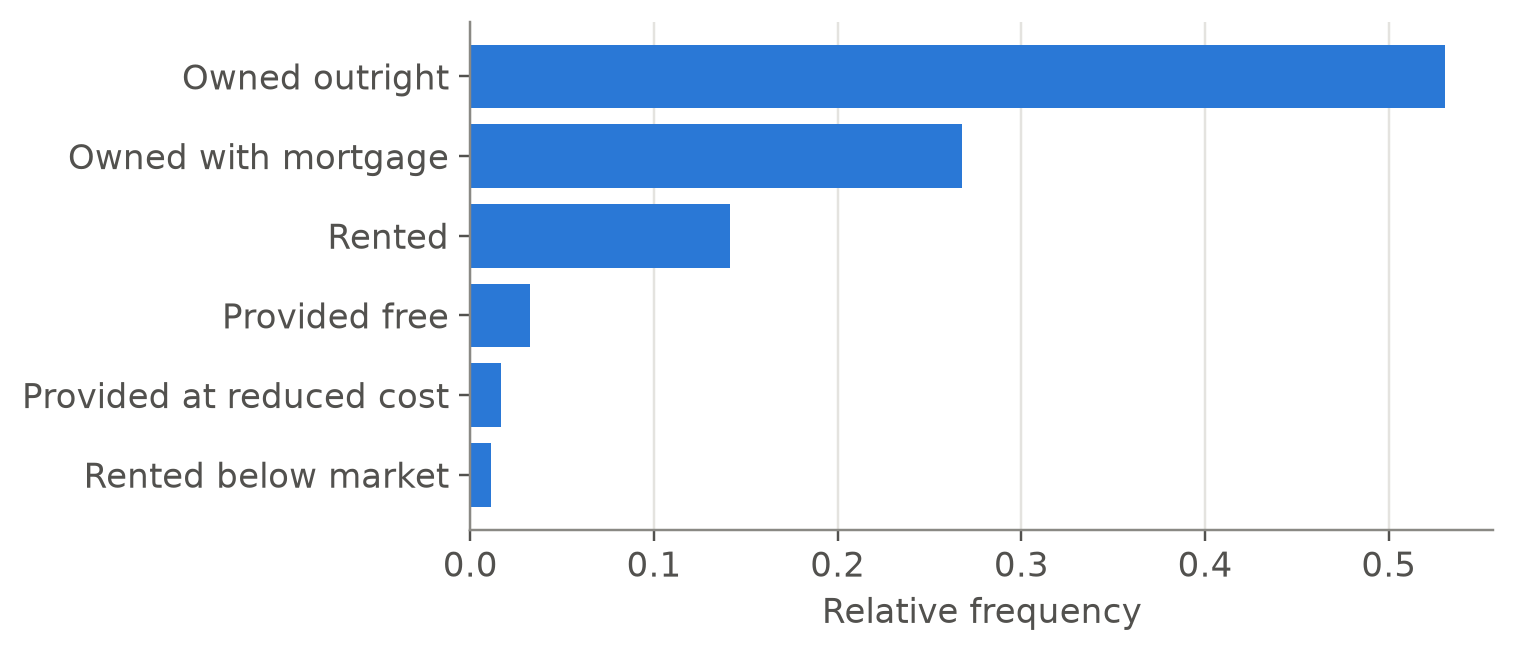

In [4]:
fig, ax = plt.subplots(figsize=(6, 3))
ax.barh(table["tenure"], table["f_i"], color=COLORS["blue"])
ax.invert_yaxis()
ax.set_xlabel("Relative frequency")
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
plt.show()

In [5]:
p_rented = table.filter(pl.col("tenure").str.starts_with("Rented"))["f_i"].sum()
print(f"Renting: {p_rented:.1%} of households")

Renting: 15.2% of households


The same result is obtained from `tenure_group`, which groups the six categories
into Owned, Rented and Other.
:::

::: {#exr-household-size}
## Household size
a) Compute the mean, median and mode of `household_size`.
b) Build the frequency table with cumulative frequencies. What proportion of
   households have at most 2 members?
c) Is the distribution symmetric? Justify your answer by comparing the measures
   of a).
:::

::: {.callout-tip collapse="true"}
## Solution

In [6]:
households.select(
    mean=pl.col("household_size").mean(),
    median=pl.col("household_size").median(),
    mode=pl.col("household_size").mode().first(),
)

mean,median,mode
2.491,2.000,2


In [7]:
table = (
    households["household_size"]
    .value_counts(name="n_i")
    .sort("household_size")
    .with_columns(f_i=pl.col("n_i") / pl.col("n_i").sum())
    .with_columns(F_i=pl.col("f_i").cum_sum())
)
table

household_size,n_i,f_i,F_i
1,4612,0.234,0.234
2,6438,0.327,0.561
3,4287,0.218,0.778
4,3411,0.173,0.952
5,724,0.037,0.988
6,173,0.009,0.997
7,47,0.002,0.999
8,6,0.000,1.000
9,2,0.000,1.000
10,1,0.000,1.000


The proportion of households with at most 2 members is $F_2 \approx 0.56$
(second row of the table): more than half of the households have one or two
members.

The mean is larger than the median and the mode, which indicates **right
skewness**: a few very large households raise the mean.
:::

::: {#exr-by-hand}
## Computing by hand
The monthly net salaries (in euros) of the 8 employees of a small firm are:
$$
1\,250 \quad 1\,400 \quad 1\,180 \quad 1\,620 \quad 1\,350 \quad 4\,900 \quad 1\,410 \quad 1\,290
$$

a) Compute **by hand** the mean, the median, the variance (dividing by $n$) and
   the standard deviation.
b) Check your results with Polars. Which argument is needed to obtain the variance
   dividing by $n$?
c) Which measure of centre best describes the "typical" salary in the firm? Why?
:::

::: {.callout-tip collapse="true"}
## Solution

a) Sorted: 1180, 1250, 1290, 1350, 1400, 1410, 1620, 4900.

- $\bar{x} = 14\,400 / 8 = 1\,800$ €.
- $Me = (1\,350 + 1\,400)/2 = 1\,375$ €.
- $s^2 = \frac{1}{8}\sum x_i^2 - \bar{x}^2$ and $s = \sqrt{s^2}$ (values in b).

b)

In [8]:
salaries = pl.Series("salary", [1250, 1400, 1180, 1620, 1350, 4900, 1410, 1290])

pl.DataFrame({
    "mean": [salaries.mean()],
    "median": [salaries.median()],
    "variance (n)": [salaries.var(ddof=0)],
    "std. dev. (n)": [salaries.std(ddof=0)],
    "corrected variance (n-1)": [salaries.var(ddof=1)],
})

mean,median,variance (n),std. dev. (n),corrected variance (n-1)
"1,800.0","1,375.0","1,388,000.0","1,178.1","1,586,285.7"


We need `ddof=0`, because by default Polars divides by $n-1$.

c) The **median**. The salary of €4,900 is an outlier and pushes the mean above
the salary of 7 of the 8 employees.
:::

::: {#exr-food}
## Food expenditure
a) Draw the density histogram of `exp_food`, the annual expenditure on food and
   non-alcoholic beverages, and describe its shape.
b) Compute the quartiles, the interquartile range and the outlier fences
   $Q_1 - 1.5\,IQR$ and $Q_3 + 1.5\,IQR$. How many households are outliers?
c) Compare the coefficient of variation of food expenditure with that of total
   expenditure, `exp_total`. Which variable is relatively more dispersed?
:::

::: {.callout-tip collapse="true"}
## Solution

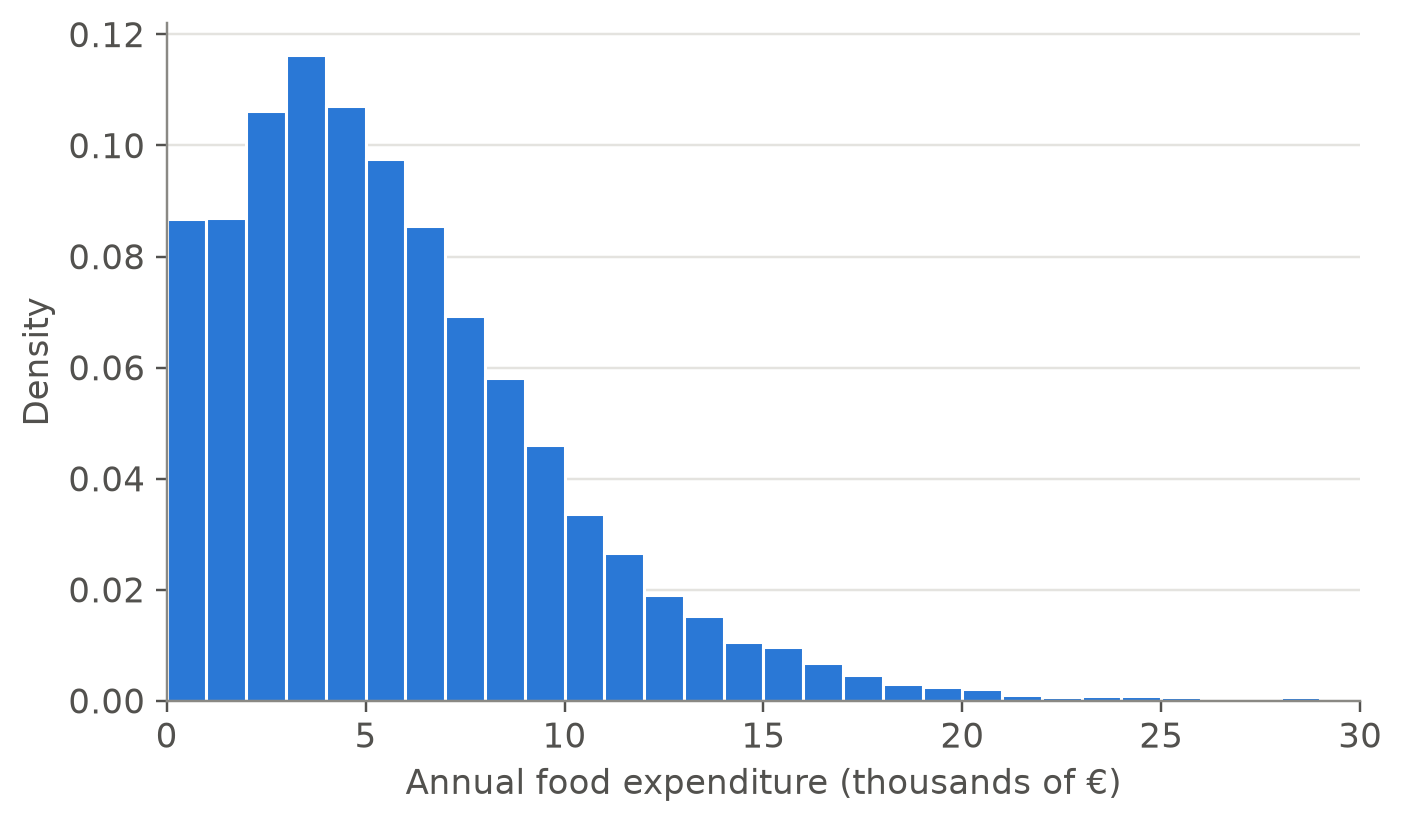

In [9]:
fig, ax = plt.subplots()
ax.hist(households["exp_food"].to_numpy() / 1000, bins=np.arange(0, 60, 1), density=True,
        color=COLORS["blue"], edgecolor="white", linewidth=1)
ax.set_xlim(0, 30)
ax.set_xlabel("Annual food expenditure (thousands of €)")
ax.set_ylabel("Density")
plt.show()

The distribution is unimodal and right-skewed: most households spend between
2,000 and 8,000 € a year on food, and a few spend much more. (The horizontal axis
is cut at 30,000 €.)

In [10]:
g = pl.col("exp_food")
q1, q2, q3 = households.select(
    q1=g.quantile(0.25, "linear"), q2=g.quantile(0.5, "linear"), q3=g.quantile(0.75, "linear")
).row(0)
iqr = q3 - q1
lf, uf = q1 - 1.5 * iqr, q3 + 1.5 * iqr
n_out = households.filter(~g.is_between(lf, uf)).height
print(f"Q1={q1:,.0f}  Me={q2:,.0f}  Q3={q3:,.0f}  IQR={iqr:,.0f}")
print(f"Fences: [{lf:,.0f}, {uf:,.0f}]  ·  Outliers: {n_out}")

Q1=2,727  Me=4,959  Q3=7,912  IQR=5,184
Fences: [-5,049, 15,688]  ·  Outliers: 550


In [11]:
households.select(
    CV_food=g.std(ddof=0) / g.mean(),
    CV_total=pl.col("exp_total").std(ddof=0) / pl.col("exp_total").mean(),
)

CV_food,CV_total
0.742,0.579


Food expenditure is relatively more dispersed: its $CV$ is larger. As explained in
[the numerical summaries](02-numerical-summaries.ipynb#measures-of-dispersion),
part of this variability comes from recording food purchases for only two weeks.
:::

::: {#exr-region}
## Expenditure by region
a) With `group_by`, compute for each region the number of households, and the
   mean, median, interquartile range and coefficient of variation of the annual
   expenditure `exp_total`.
b) Sort the table by the median. Which region has the highest median expenditure?
c) In which region is expenditure relatively most dispersed? How many households
   of that region are in the sample?
:::

::: {.callout-tip collapse="true"}
## Solution

In [12]:
r = pl.col("exp_total")
by_region = (
    households.group_by("region")
    .agg(
        n=pl.len(),
        mean=r.mean(),
        median=r.median(),
        IQR=r.quantile(0.75, "linear") - r.quantile(0.25, "linear"),
        CV=r.std(ddof=0) / r.mean(),
    )
    .sort("median", descending=True)
)
by_region

region,n,mean,median,IQR,CV
Madrid,1755,"42,973.6","37,502.2","26,667.0",0.568
Basque Country,2059,"40,080.9","35,425.2","25,711.0",0.538
Catalonia,1440,"40,411.3","34,884.8","25,447.7",0.575
Balearic Islands,506,"38,298.5","33,435.0","22,870.7",0.531
Navarre,575,"36,029.1","32,546.7","21,464.1",0.511
Aragon,954,"36,087.2","32,208.4","22,468.6",0.545
Cantabria,690,"35,646.2","31,923.0","21,817.8",0.544
La Rioja,555,"34,872.6","31,743.9","22,045.6",0.498
Valencian Community,1706,"35,372.0","30,894.2","22,593.1",0.580
Murcia,926,"34,535.5","30,541.7","23,150.2",0.583


In [13]:
max_cv = by_region.sort("CV", descending=True).row(0, named=True)
print(f"Largest relative dispersion: {max_cv['region']} "
      f"(CV = {max_cv['CV']:.2f}, n = {max_cv['n']})")

Largest relative dispersion: Melilla (CV = 0.68, n = 114)


The regions with few households in the sample (Ceuta and Melilla) give less
reliable summaries: a handful of unusual households can change their $CV$
noticeably.
:::

::: {#exr-units}
## Change of units
We want to express the annual expenditure in **thousands of euros at 2024 prices**, knowing that
prices rose by 3 % between 2024 and 2025 (the year of the survey). That is,
$y_i = x_i / (1\,000 \cdot 1.03)$.

a) Without a computer, how do the mean and the standard deviation change? And the
   coefficient of variation?
b) Check it with Polars.
:::

::: {.callout-tip collapse="true"}
## Solution

a) It is a linear transformation $y = b\,x$ with $b = 1/1\,030$. Hence
$\bar{y} = \bar{x}/1\,030$ and $s_y = s_x/1\,030$
([linear transformations](02-numerical-summaries.ipynb#linear-transformations)).
The $CV$ **does not change**, because the factor $b$ cancels in the ratio.

b)

In [14]:
b = 1 / (1000 * 1.03)
x = pl.col("exp_total")
y = x * b

households.select(
    mean_x=x.mean(), mean_y=y.mean(), mean_x_times_b=x.mean() * b,
    s_x=x.std(ddof=0), s_y=y.std(ddof=0),
    CV_x=x.std(ddof=0) / x.mean(), CV_y=y.std(ddof=0) / y.mean(),
)

mean_x,mean_y,mean_x_times_b,s_x,s_y,CV_x,CV_y
"35,705.2",34.665,34.665,"20,657.7",20.056,0.579,0.579


:::